In [2]:
from pathlib import Path
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import pandas as pd

In [29]:
BASE = 'C:/Users/tjsss/OneDrive/Desktop/machine learning/crackLens/data/CRACK500/traincrop/'
crack500_train_dir = 'C:/Users/tjsss/OneDrive/Desktop/machine learning/crackLens/data/CRACK500/train.txt'
with open(crack500_train_dir, 'r') as f:
    lines = f.readlines()
    image_paths = [[line.strip().split(' ')[0] , line.strip().split(' ')[1]]for line in lines]
    

In [30]:
len(image_paths[1892])

2

In [31]:
def show_image(image_path, mask_path):
    img = np.array(Image.open(image_path).convert('RGB'))
    m = np.array(Image.open(mask_path).convert('L'))
    
    if m.ndim == 3:
        m = m[..., 0]
        
    print(f"Image shape: {img.shape}, Mask shape: {m.shape}" ,
          "| mask values", np.unique(m),
          "| crack %", round(100 * (m>127).mean() , 2))
    
    overlay = img.copy()
    overlay[m>127] = [255, 0, 0]
    fig, ax = plt.subplots(1, 3, figsize=(15, 5))
    
    for a, im, t in zip(ax, [img, m, overlay], ['Image', 'Mask', 'Overlay']):
        a.imshow(im)
        a.set_title(t)
        a.axis('off')
        
    plt.show()

Image shape: (360, 640, 3), Mask shape: (360, 640) | mask values [  0 255] | crack % 11.79


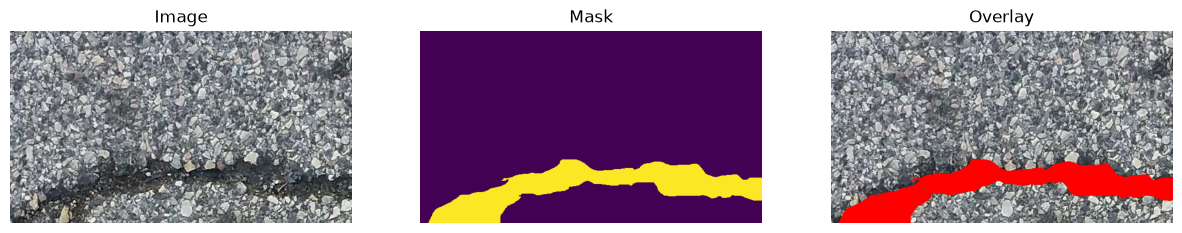

Image shape: (360, 640, 3), Mask shape: (360, 640) | mask values [  0 255] | crack % 3.03


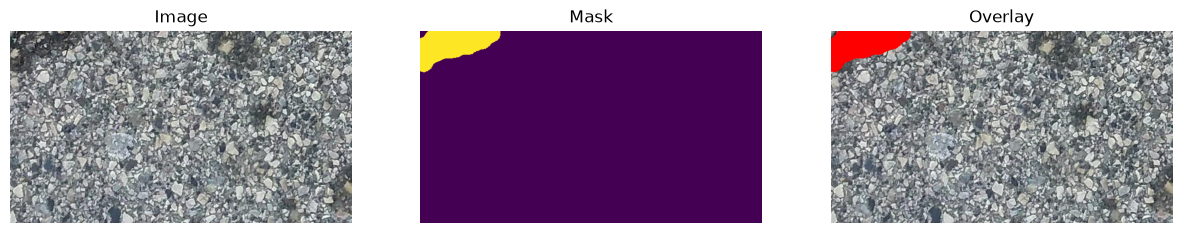

Image shape: (360, 640, 3), Mask shape: (360, 640) | mask values [  0 255] | crack % 3.63


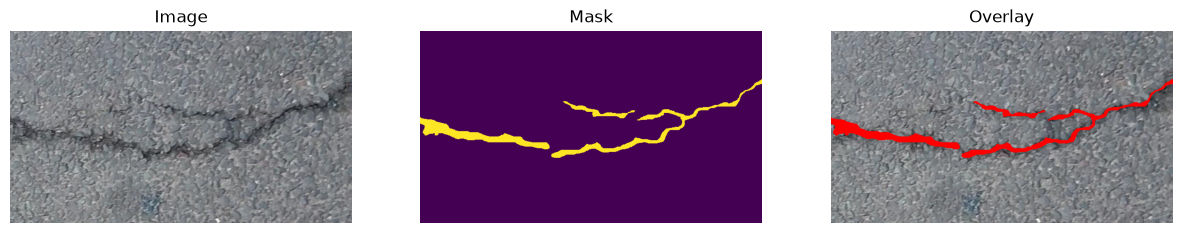

Image shape: (360, 640, 3), Mask shape: (360, 640) | mask values [  0 255] | crack % 2.94


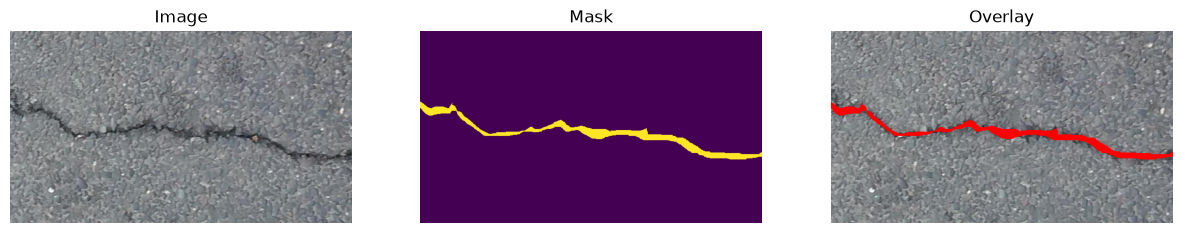

Image shape: (360, 640, 3), Mask shape: (360, 640) | mask values [  0 255] | crack % 0.46


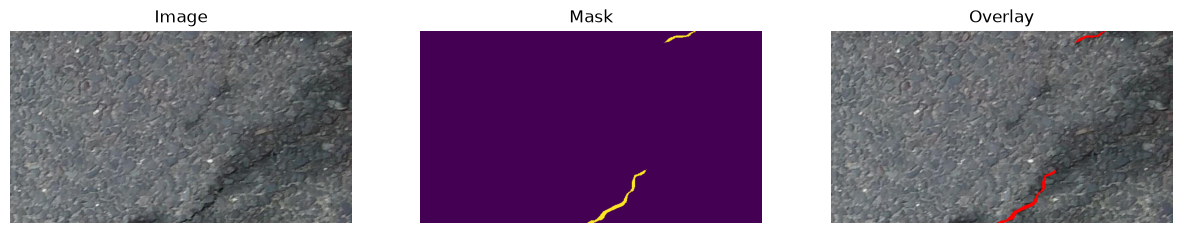

In [33]:
for i in range(10,15):
    show_image(BASE + image_paths[i][0], BASE + image_paths[i][1])

In [38]:
diff_ls = []
diff = 0
for i in range(len(image_paths)):
    img = np.array(Image.open(BASE + image_paths[i][0]).convert('RGB'))
    mask = np.array(Image.open(BASE + image_paths[i][1]).convert('L'))
    
    diff_ls.append(i) if img.shape[:2] != mask.shape[:2] else 0
    diff += 1 if img.shape[:2] != mask.shape[:2] else 0
    
    
print(diff, diff_ls)

0 []


## FOR CRACK500

In [ ]:

crack500_path = Path('C:/Users/tjsss/OneDrive/Desktop/machine learning/crackLens/data/CRACK500/traincrop/')

def scan(folder):
    files = list(folder.iterdir())
    imgs = {p.stem: p for p in files if p.suffix.lower() == '.jpg'}
    masks = {p.stem: p for p in files if p.suffix.lower() == '.png'}

    print(f"Found {len(imgs)} images and {len(masks)} masks in {folder}")

    rows = []
    for k in sorted(set(imgs) & set(masks)):
        with Image.open(imgs[k]) as a, Image.open(masks[k]) as b:
            (w , h) , (mw , mh) = a.size, b.size

        m = np.array(Image.open(masks[k]).convert('L'))
        if m.ndim == 3:
            m = m[..., 0]

        rows.append(dict(name = k , 
                         width = w , 
                         height = h , 
                         same_size = (w , h) == (mw , mh), 
                         mask_values = str(np.unique(m)[:6]) , 
                         crack_percent = round(100 * (m>127).mean() , 2)))
        
    print(files)

    return pd.DataFrame(rows)
    

In [68]:
df = scan(crack500_path)
print(df.same_size.value_counts())
print(df.mask_values.value_counts().head())
print(df.crack_percent.describe()[['count' , 'mean' , 'std' , 'min' , 'max']])
print(df[['width' , 'height']].describe())

Found 1896 images and 1896 masks in C:\Users\tjsss\OneDrive\Desktop\machine learning\crackLens\data\CRACK500\traincrop
[WindowsPath('C:/Users/tjsss/OneDrive/Desktop/machine learning/crackLens/data/CRACK500/traincrop/20160222_081011_1281_721.jpg'), WindowsPath('C:/Users/tjsss/OneDrive/Desktop/machine learning/crackLens/data/CRACK500/traincrop/20160222_081011_1281_721.png'), WindowsPath('C:/Users/tjsss/OneDrive/Desktop/machine learning/crackLens/data/CRACK500/traincrop/20160222_081011_1921_721.jpg'), WindowsPath('C:/Users/tjsss/OneDrive/Desktop/machine learning/crackLens/data/CRACK500/traincrop/20160222_081011_1921_721.png'), WindowsPath('C:/Users/tjsss/OneDrive/Desktop/machine learning/crackLens/data/CRACK500/traincrop/20160222_081011_1_361.jpg'), WindowsPath('C:/Users/tjsss/OneDrive/Desktop/machine learning/crackLens/data/CRACK500/traincrop/20160222_081011_1_361.png'), WindowsPath('C:/Users/tjsss/OneDrive/Desktop/machine learning/crackLens/data/CRACK500/traincrop/20160222_081011_1_721.

In [3]:
deepCracks_path = Path('C:\\Users\\tjsss\\OneDrive\\Desktop\\machine learning\\crackLens\\data\\DeepCrack\\')

def scan_dc(folder):

    train_img = 'train_img'
    train_mask = 'train_lab'

    imgs = {f.stem: f for f in Path(folder / train_img).iterdir() if f.suffix.lower() == '.jpg'}
    masks = {f.stem: f for f in Path(folder / train_mask).iterdir() if f.suffix.lower() == '.png'}
            
    print(f"Found {len(imgs)} images and {len(masks)} masks in {folder}")
        
    rows = []
    for k in sorted(set(imgs) & set(masks)):
            with Image.open(imgs[k]) as a, Image.open(masks[k]) as b:
                (w , h) , (mw , mh) = a.size, b.size
        
            m = np.array(Image.open(masks[k]).convert('L'))
            if m.ndim == 3:
                m = m[..., 0]
        
            rows.append(dict(name = k , 
                            width = w , 
                            height = h , 
                            same_size = (w , h) == (mw , mh), 
                            mask_values = str(np.unique(m)[:6]) , 
                            crack_percent = round(100 * (m>127).mean() , 2)))
                

    return pd.DataFrame(rows)

In [82]:
df_dc = scan_dc(deepCracks_path)
print(df_dc.same_size.value_counts())
print(df_dc.mask_values.value_counts().head())
print(df_dc.crack_percent.describe()[['count' , 'mean' , 'std' , 'min' , 'max']])
print(df_dc[['width' , 'height']].describe())

Found 300 images and 300 masks in C:\Users\tjsss\OneDrive\Desktop\machine learning\crackLens\data\DeepCrack
same_size
True    300
Name: count, dtype: int64
mask_values
[  0 255]    300
Name: count, dtype: int64
count    300.000000
mean       2.912933
std        2.487641
min        0.260000
max       19.940000
Name: crack_percent, dtype: float64
       width  height
count  300.0   300.0
mean   544.0   384.0
std      0.0     0.0
min    544.0   384.0
25%    544.0   384.0
50%    544.0   384.0
75%    544.0   384.0
max    544.0   384.0


In [7]:
import json, base64, zlib, io
from pathlib import Path
import numpy as np, pandas as pd
from PIL import Image

ds  = Path(r"C:\Users\tjsss\OneDrive\Desktop\machine learning\crackLens\data\concrete-crack-segmentation-DatasetNinja\ds")
out = ds.parents[1] / "ozgenel_masks"          # data\ozgenel_masks, separate from the download
out.mkdir(exist_ok=True)

def decode_bitmap(b64):
    a = np.array(Image.open(io.BytesIO(zlib.decompress(base64.b64decode(b64)))))
    if a.ndim == 3:
        a = a[..., 3] if a.shape[-1] == 4 else a[..., 0]
    return a > 0

def load_mask(ann_path):
    ann = json.loads(ann_path.read_text())
    H, W = ann["size"]["height"], ann["size"]["width"]
    full = np.zeros((H, W), bool)
    for o in ann["objects"]:
        if o["geometryType"] != "bitmap":
            continue
        x, y = o["bitmap"]["origin"]
        m = decode_bitmap(o["bitmap"]["data"])
        full[y:y + m.shape[0], x:x + m.shape[1]] |= m
    return full, len(ann["objects"])

rows = []
for ap in sorted((ds / "ann").glob("*.json")):
    photo = ds / "img" / ap.name[:-5]
    try:
        mask, n_obj = load_mask(ap)
        Image.fromarray(mask.astype(np.uint8) * 255).save(out / f"{photo.stem}.png")
        with Image.open(photo) as im:
            pw, ph = im.size
            exif = im.getexif().get(274)
        rows.append(dict(name=photo.name, photo_w=pw, photo_h=ph, size_match=(ph, pw) == mask.shape,
                         exif=exif, objects=n_obj, crack_pct=round(100 * mask.mean(), 2)))
    except Exception as e:
        print("FAILED", ap.name, repr(e))

df_oz = pd.DataFrame(rows)
print(len(df_oz), "converted |", len(list(out.glob("*.png"))), "png files")
print(df_oz.size_match.value_counts().to_dict(), df_oz.exif.value_counts(dropna=False).to_dict())
print(df_oz.groupby(["photo_w", "photo_h"]).size())
print(df_oz.crack_pct.describe(percentiles=[.05, .5, .95]))

458 converted | 458 png files
{True: 279, False: 179} {nan: 257, 6.0: 179, 3.0: 15, 1.0: 7}
photo_w  photo_h
2448     3264         7
3264     2448        13
4032     3024       438
dtype: int64
count    458.000000
mean       1.615153
std        0.751251
min        0.580000
5%         0.840000
50%        1.440000
95%        2.831500
max        9.020000
Name: crack_pct, dtype: float64


In [8]:
from PIL import Image, ImageOps
bad = []
for photo in sorted((ds/"img").iterdir()):
    mask = np.array(Image.open(out/f"{photo.stem}.png"))
    img  = ImageOps.exif_transpose(Image.open(photo))
    if (img.height, img.width) != mask.shape:
        bad.append(photo.name)
print(len(bad), "mismatches (expect 0)")

0 mismatches (expect 0)
